<div style="background:linear-gradient(135deg,#0f3d6e,#1f6fb2);color:#ffffff;padding:22px 26px;border-radius:10px;margin-bottom:18px">
  <span style="font-size:12px;letter-spacing:1.5px;text-transform:uppercase;opacity:0.85">INF432 · Minería de datos para decisiones comerciales · Segundo examen</span>
  <h1 style="margin:8px 0 4px;font-size:24px;color:#ffffff">Cuaderno 03: Área 3 · Patrones de Compra y Evaluación Final (A3)</h1>
  <p style="margin:0;font-size:13px;opacity:0.9">Grupo: <strong>RetailAnalytics</strong> · Integrantes: Diego Fernando Banegas Bruno, Hernandez Lijeron Roly, Huanca Silvestre Grover</p>
</div>


In [1]:
# 1. IMPORTAR LIBRERÍAS Y CONFIGURACIÓN
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

SEMILLA = 1  # Semilla fija para total reproducibilidad
ks = range(2, 11)  # Rango de K a evaluar (2 a 10)


In [2]:
# 2. CARGAR EL DATASET PREPARADO EN EL CUADERNO 00
df_limpio = pd.read_csv("data/processed/clientes_limpio.csv")
print("Datos cargados correctamente:", df_limpio.shape)


Datos cargados correctamente: (2025, 34)


# 5.3 ÁREA 3: PATRONES DE COMPRA (A3)

**Pregunta de negocio:** ¿Qué patrones de compra se repiten entre los clientes según su recencia, frecuencia, monto (RFM), canal preferido (web, catálogo o tienda) y uso de descuentos, y por qué canal conviene llegar a cada patrón?

- **Decisión que apoya:** en qué canal invertir y qué tipo de oferta enviar a cada patrón de compra.
- **Quién decide:** el jefe de canales de venta (tienda física y e-commerce).
- **Criterio de éxito:** identificar entre 3 y 5 patrones con silueta mayor a 0.25 y diferencias claras en RFM o canal preferido.

**Tipo de problema:** no supervisado (agrupamiento).

## 5.3.1 Reducción de dimensionalidad (si aplica)

*PCA: varianza explicada, número de componentes y gráfico 2D (lecciones 1.3 y 1.6-1.7). LDA o t-SNE para comparar (lecciones 1.4 y 1.5).*

In [3]:
# Celda de código, variables de comportamiento:

df_limpio['Pct_Web']       = (df_limpio['NumWebPurchases'] / df_limpio['Compras_Total']).fillna(0)      # % de compras por web
df_limpio['Pct_Catalogo']  = (df_limpio['NumCatalogPurchases'] / df_limpio['Compras_Total']).fillna(0)  # % por catálogo
df_limpio['Pct_Tienda']    = (df_limpio['NumStorePurchases'] / df_limpio['Compras_Total']).fillna(0)    # % en tienda
df_limpio['Pct_Descuento'] = (df_limpio['NumDealsPurchases'] / df_limpio['Compras_Total']).fillna(0).clip(upper=1)  # % con descuento

vars_rfm = ['Recency', 'Compras_Total', 'Gasto_Total',                       # R, F, M
            'Pct_Web', 'Pct_Catalogo', 'Pct_Tienda', 'Pct_Descuento',        # Canal y descuentos
            'NumWebVisitsMonth']                                             # Interés digital
rfm = df_limpio[vars_rfm]                                                    # Unidades originales (para perfilar)
rfm_s = StandardScaler().fit_transform(rfm)                                  # Estandarizado (para k-means)
rfm.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Recency,2025.0,48.91,28.97,0.0,24.00,49.00,74.00,99.0
Compras_Total,2025.0,12.56,7.19,0.0,6.00,12.00,18.00,32.0
Gasto_Total,2025.0,607.71,603.46,5.0,69.00,397.00,1048.00,2525.0
Pct_Web,2025.0,0.33,0.12,0.0,0.25,0.33,0.40,1.0
Pct_Catalogo,2025.0,0.16,0.14,0.0,0.00,0.15,0.25,1.0
Pct_Tienda,2025.0,0.50,0.15,0.0,0.40,0.50,0.60,1.0
Pct_Descuento,2025.0,0.24,0.17,0.0,0.08,0.20,0.33,1.0
NumWebVisitsMonth,2025.0,5.33,2.44,0.0,3.00,6.00,7.00,20.0


,PC1,PC2
Recency,0.01,0.00
Compras_Total,0.45,0.16
Gasto_Total,0.47,0.05
Pct_Web,-0.15,0.67
Pct_Catalogo,0.44,0.06
Pct_Tienda,-0.28,-0.60
Pct_Descuento,-0.39,0.12
NumWebVisitsMonth,-0.36,0.38


Varianza explicada por PC1 + PC2: 65.58%


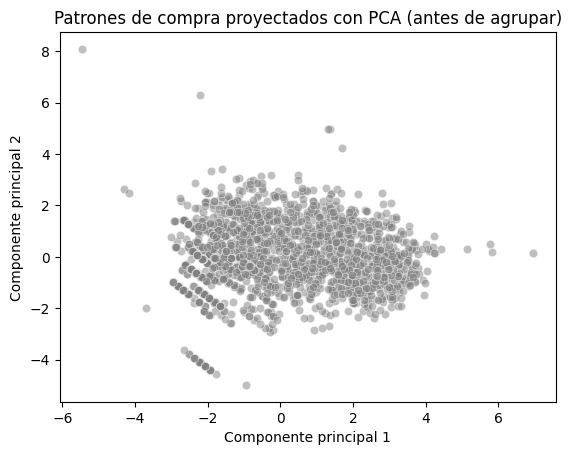

In [4]:

pca_rfm = PCA(n_components=2)                                                # 2 componentes para graficar
rfm_pca = pca_rfm.fit_transform(rfm_s)
print("Varianza explicada por PC1 + PC2: {:.2%}".format(pca_rfm.explained_variance_ratio_.sum()))
display(pd.DataFrame(pca_rfm.components_.T, index=vars_rfm, columns=['PC1', 'PC2']).round(2))  # Cargas

sns.scatterplot(x=rfm_pca[:, 0], y=rfm_pca[:, 1], alpha=0.5, color='gray')
plt.title('Patrones de compra proyectados con PCA (antes de agrupar)')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.show()

¿Qué observamos?

Las 2 componentes explican el 65.58 % de la varianza.
PC1 = “valor y catálogo vs. cazador de ofertas”: a la derecha pesan Gasto_Total (0.47), Compras_Total (0.45) y Pct_Catalogo (0.44); a la izquierda, Pct_Descuento (−0.39) y NumWebVisitsMonth (−0.36). Los clientes que más compran usan el catálogo y casi no buscan descuentos; los que compran poco navegan mucho la web y compran en oferta.
PC2 = “digital vs. tienda física”: arriba Pct_Web (0.67) y abajo Pct_Tienda (−0.60).
Recency casi no pesa en ninguna (0.01): cuándo compró por última vez es independiente de cómo compra.
Se ven líneas diagonales y puntos aislados abajo a la izquierda: son clientes con muy pocas compras (1 o 2), cuyos porcentajes quedan en valores extremos como 0 % o 100 %.

## 5.3.2 Modelado

*Si es **agrupamiento**: elección de K con la silueta (lección 2.4), segundo método (jerárquico, lección 2.3, o DBSCAN, lección 2.5) y perfil de cada grupo en unidades originales con `groupby(...).mean()`.*

*Si es **clasificación**: kNN y árbol optimizados con `GridSearchCV`, Naive Bayes, y para cada modelo la matriz de confusión y la exactitud en los datos de **prueba** (lecciones 3.3 a 3.5).*

K = 2: silueta = 0.315
K = 3: silueta = 0.248
K = 4: silueta = 0.194
K = 5: silueta = 0.195
K = 6: silueta = 0.185
K = 7: silueta = 0.164
K = 8: silueta = 0.168
K = 9: silueta = 0.163
K = 10: silueta = 0.167


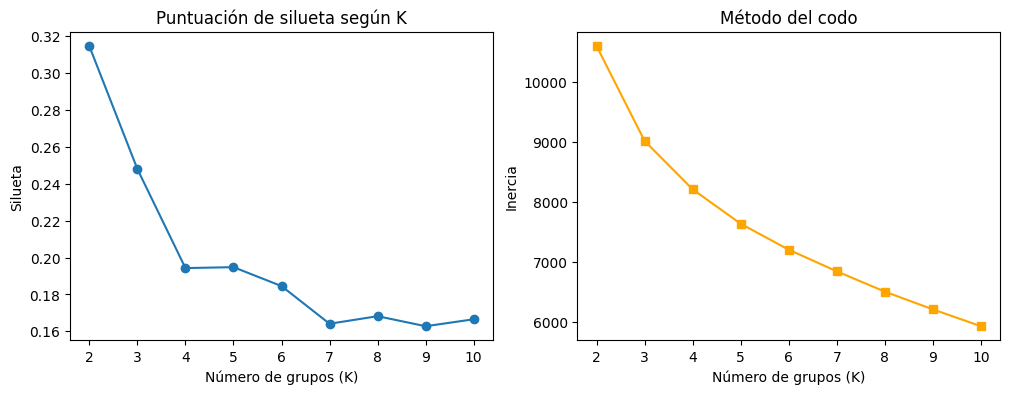

In [5]:
siluetas_rfm, inercias_rfm = [], []
for k in ks:                                                       # ks = range(2, 11), definido en el Área 2
    km_k = KMeans(n_clusters=k, random_state=SEMILLA, init='k-means++', n_init=10)  # Modelo con K grupos
    etiquetas = km_k.fit_predict(rfm_s)                            # Agrupa los patrones de compra
    siluetas_rfm.append(silhouette_score(rfm_s, etiquetas))        # Separación de los grupos
    inercias_rfm.append(km_k.inertia_)                             # Compacidad de los grupos

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, siluetas_rfm, 'o-')
axes[0].set_title('Puntuación de silueta según K')
axes[0].set_xlabel('Número de grupos (K)')
axes[0].set_ylabel('Silueta')
axes[1].plot(ks, inercias_rfm, 's-', color='orange')
axes[1].set_title('Método del codo')
axes[1].set_xlabel('Número de grupos (K)')
axes[1].set_ylabel('Inercia')
plt.show()

for k, s in zip(ks, siluetas_rfm):
    print("K = {}: silueta = {:.3f}".format(k, s))

¿Qué observamos? (elección de K)

La silueta más alta es K = 2 (0.315), pero dos patrones son muy pocos para decidir en qué canales invertir.
K = 3 tiene la mejor silueta entre las opciones útiles (0.248), muy por encima de K = 4 a 10 (0.16 a 0.19). El codo también se suaviza a partir de K = 3 o 4.
Decisión: K = 3. La silueta queda prácticamente en el umbral del criterio de éxito (0.25), así que los patrones tienen cierta superposición.

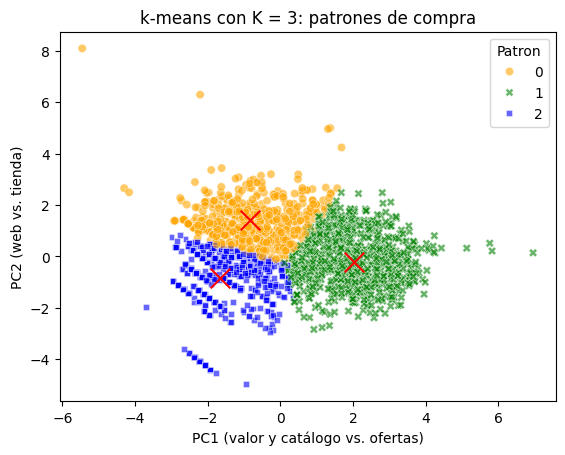

Patron,0,1,2
Recency,48.74,49.60,48.27
Compras_Total,11.48,19.29,5.74
Gasto_Total,359.55,1216.24,107.07
Pct_Web,0.46,0.28,0.29
Pct_Catalogo,0.13,0.28,0.06
Pct_Tienda,0.40,0.44,0.65
Pct_Descuento,0.33,0.10,0.34
NumWebVisitsMonth,7.22,3.48,5.97
Response,0.18,0.22,0.06
Clientes,536.00,792.00,697.00


In [6]:
# k-means final y perfil de los patrones

km_rfm = KMeans(n_clusters=3, random_state=SEMILLA, init='k-means++', n_init=10)  # Modelo final del Área 3
df_limpio['Patron'] = km_rfm.fit_predict(rfm_s)                    # Patrón de compra de cada cliente
centros_rfm = pca_rfm.transform(km_rfm.cluster_centers_)           # Centroides en el plano del PCA

sns.scatterplot(x=rfm_pca[:, 0], y=rfm_pca[:, 1], hue=df_limpio['Patron'], style=df_limpio['Patron'],
                palette=['orange', 'green', 'blue'], alpha=0.6)
plt.scatter(centros_rfm[:, 0], centros_rfm[:, 1], marker='x', s=200, c='red')    # Centroides
plt.title('k-means con K = 3: patrones de compra')
plt.xlabel('PC1 (valor y catálogo vs. ofertas)')
plt.ylabel('PC2 (web vs. tienda)')
plt.show()

perfil_rfm = df_limpio.groupby('Patron')[vars_rfm + ['Response']].mean().round(2)   # Promedios en unidades originales
perfil_rfm['Clientes'] = df_limpio['Patron'].value_counts().sort_index()
perfil_rfm['% del total'] = (perfil_rfm['Clientes'] / len(df_limpio) * 100).round(1)
perfil_rfm.T                                                       # Volteada para leerla completa

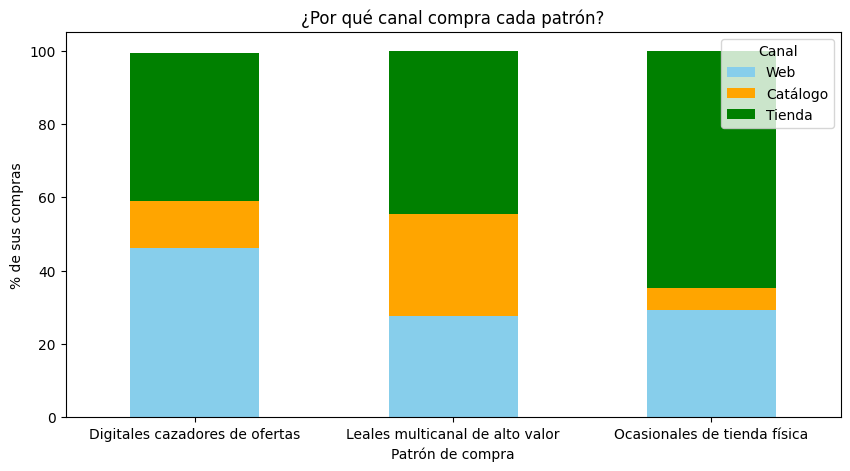

In [7]:
# nombres comerciales y gráfico de canales

nombres_rfm = {0: 'Digitales cazadores de ofertas', 1: 'Leales multicanal de alto valor', 2: 'Ocasionales de tienda física'}
df_limpio['Nombre_Patron'] = df_limpio['Patron'].map(nombres_rfm)          # Nombre comercial de cada cliente
perfil_rfm.index = perfil_rfm.index.map(nombres_rfm)                        # Nombres en la tabla de perfiles

canal = df_limpio.groupby('Nombre_Patron')[['Pct_Web', 'Pct_Catalogo', 'Pct_Tienda']].mean() * 100  # % por canal
canal.plot(kind='bar', stacked=True, figsize=(10, 5), color=['skyblue', 'orange', 'green'])        # Barras apiladas al 100 %
plt.title('¿Por qué canal compra cada patrón?')
plt.xlabel('Patrón de compra')
plt.ylabel('% de sus compras')
plt.xticks(rotation=0)
plt.legend(['Web', 'Catálogo', 'Tienda'], title='Canal')
plt.show()

¿Qué observamos? Los Digitales cazadores de ofertas hacen casi la mitad de sus compras por web (46 %). Los Leales multicanal reparten sus compras entre los 3 canales y son los que más usan el catálogo (28 %). Los Ocasionales de tienda física compran sobre todo en tienda (65 %) y casi nunca por catálogo (6 %).

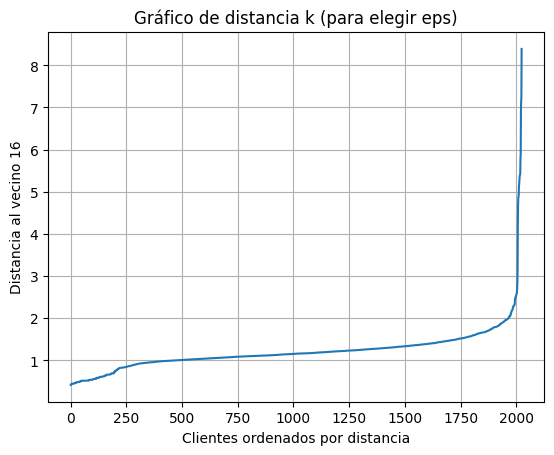

In [8]:
# DBSCAN (segundo método)

from sklearn.neighbors import NearestNeighbors        # Para calcular distancias a los vecinos
from sklearn.cluster import DBSCAN                    # Agrupamiento por densidad

min_muestras = 2 * rfm_s.shape[1]                     # Regla práctica: 2 × número de variables = 16
vecinos = NearestNeighbors(n_neighbors=min_muestras).fit(rfm_s)
distancias, _ = vecinos.kneighbors(rfm_s)             # Distancia de cada cliente a sus 16 vecinos más cercanos
dist_k = np.sort(distancias[:, -1])                   # Distancia al vecino 16, ordenada de menor a mayor

plt.plot(dist_k)
plt.title('Gráfico de distancia k (para elegir eps)')
plt.xlabel('Clientes ordenados por distancia')
plt.ylabel('Distancia al vecino 16')
plt.grid(True)
plt.show()

se mantiene plana hasta cerca del cliente 1950 y se dispara alrededor de distancia = 2. Ese es el codo, así que usamos eps = 2.0.

DBSCAN,-1,0,1
k-means,,,
Digitales cazadores de ofertas,11,525,0
Leales multicanal de alto valor,7,785,0
Ocasionales de tienda física,7,666,24


Grupos encontrados por DBSCAN (-1 = ruido):
DBSCAN
-1      25
 0    1976
 1      24
Name: count, dtype: int64


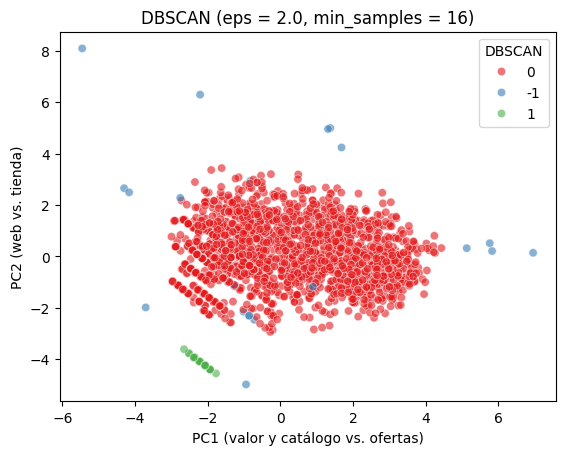

,0
Recency,44.68
Compras_Total,9.24
Gasto_Total,467.52
Pct_Web,0.23
Pct_Catalogo,0.28
Pct_Tienda,0.26
Pct_Descuento,0.34
NumWebVisitsMonth,8.08


In [9]:
# DBSCAN y compararlo con k-means.

dbscan = DBSCAN(eps=2.0, min_samples=min_muestras)               # eps tomado del codo de la curva
df_limpio['DBSCAN'] = dbscan.fit_predict(rfm_s)                   # -1 = ruido (cliente atípico)
print("Grupos encontrados por DBSCAN (-1 = ruido):")
print(df_limpio['DBSCAN'].value_counts().sort_index())

sns.scatterplot(x=rfm_pca[:, 0], y=rfm_pca[:, 1], hue=df_limpio['DBSCAN'].astype(str),
                palette='Set1', alpha=0.6)                        # Ruido y grupos de DBSCAN
plt.title('DBSCAN (eps = 2.0, min_samples = 16)')
plt.xlabel('PC1 (valor y catálogo vs. ofertas)')
plt.ylabel('PC2 (web vs. tienda)')
plt.show()

display(pd.crosstab(df_limpio['Nombre_Patron'], df_limpio['DBSCAN'],
                    rownames=['k-means'], colnames=['DBSCAN']))  # Cómo se reparten los patrones de k-means
df_limpio[df_limpio['DBSCAN'] == -1][vars_rfm].mean().round(2)    # Perfil promedio de los clientes atípicos


¿Qué observamos? (k-means vs DBSCAN)

DBSCAN pone al 97.6 % de los clientes (1976) en un solo grupo denso. Los patrones de compra no forman islas separadas sino una nube continua, y eso explica la silueta moderada de k-means (0.248).
k-means divide esa nube en 3 patrones útiles para decidir canales. DBSCAN, en cambio, sirve para detectar lo raro:
25 clientes atípicos (ruido): salen de los 3 patrones (11, 7 y 7). Tienen un comportamiento mezclado: visitan mucho la web (8 visitas al mes), usan bastante el catálogo (28 %) y compran con descuento (34 %).
Un micro nicho de 24 clientes, todos Ocasionales de tienda física, ubicados abajo en el eje web vs. tienda. Son clientes de comportamiento muy parecido, concentrado en la tienda física.
Conclusión: k-means es el método principal para la estrategia de canales, y DBSCAN lo complementa marcando los clientes que conviene revisar por separado.

## 5.3.3 Interpretación para el negocio

*¿Qué responde este resultado a la pregunta de negocio? ¿Qué decisión recomiendan? ¿Qué error es más costoso?*

Respuesta a la pregunta: hay 3 patrones de compra que se diferencian por la frecuencia, el monto y el canal (no por la recencia, que es igual en todos, unos 49 días).

Recomendación por patrón:

Leales multicanal de alto valor (39 %, gasto 1 216, aceptan campañas el 22 %): son el motor de las ventas y usan mucho el catálogo. Conviene mantener e invertir en el catálogo y en un programa de fidelidad. No darles descuentos (solo el 10 % de sus compras son en oferta): comprarían igual, y el descuento sería margen perdido.
Digitales cazadores de ofertas (27 %, 46 % por web, 7.2 visitas al mes): visitan mucho la web pero compran poco. Hay que llegarles con promociones por correo y ofertas en la web (ofertas relámpago, recordatorios del carrito) para convertir esas visitas en compras.
Ocasionales de tienda física (34 %, solo 5.7 compras, aceptan el 6 %): no conviene gastar en campañas telefónicas con ellos. Mejor promociones dentro de la tienda y una tarjeta de puntos que premie volver, para subir su frecuencia.
Los 25 clientes atípicos que marcó DBSCAN deben revisarse uno por uno antes de incluirlos en campañas.

Despliegue: cada mes se recalcula el patrón de cada cliente con km_rfm.predict() y el CRM lo etiqueta. El jefe de canales usa la etiqueta para decidir qué oferta y por qué canal enviarla.

Monitoreo: seguir mes a mes cuántos Ocasionales pasan a Leales (objetivo de la tarjeta de puntos) y la tasa de conversión web de los Digitales.

Limitaciones: la silueta (0.248) quedó justo debajo del 0.25 del criterio de éxito, por lo que este se cumple parcialmente: los patrones se superponen en sus bordes.

# 6. EVALUACIÓN Y CONCLUSIONES

*Comparen los resultados con los criterios de éxito de cada área y resuman las recomendaciones. Estas conclusiones deben coincidir con las del documento y las diapositivas.*

Resultados frente a los criterios de éxito

Área	Criterio de éxito	Resultado	¿Cumple?
1. Campañas (supervisada)	Detectar ≥ 60 % de los aceptantes y precisión > 15 %	Árbol: detecta el 68.8 % con precisión del 34.6 %	 Sí
2. Segmentación (no supervisada)	3 a 6 grupos, silueta > 0.25, perfiles distintos	3 segmentos, silueta 0.268	 Sí
3. Patrones de compra (no supervisada)	3 a 5 patrones, silueta > 0.25, diferencias en RFM o canal	3 patrones, silueta 0.248	 Parcial

Conclusiones integradas

Las 3 áreas apuntan al mismo hallazgo: un grupo reducido de clientes de alto valor sostiene el negocio. Los Premium sin hijos (22 % de los clientes) generan el 51 % de las ventas y aceptan el 28 % de las campañas, y los Leales multicanal son los que más compran y más responden.
Recomendación general: dejar de tratar a todos los clientes igual. Concentrar las campañas telefónicas en los que el árbol marca como “Acepta” (en su mayoría de estos grupos de alto valor), y atender a los grupos de bajo gasto con canales baratos (web, correo y promociones en tienda).
Llamar a todos genera pérdida (−801), mientras que usar el modelo genera ganancia y más del doble de tasa de aceptación.

Limitaciones generales: los datos son de 2012 a 2014 y no sabemos de qué país ni de qué empresa vienen. Los costos de contacto e ingreso (3 y 11) no están documentados. La clase está desbalanceada (15 %) y los grupos se superponen en sus bordes.

# REFERENCIAS

*Conjuntos de datos, notebooks y artículos consultados (formato APA), y herramientas de IA usadas.*

*-Patel, A. (2021). Customer Personality Analysis [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis
*-Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C. y Wirth, R. (2000). CRISP-DM 1.0: Step-by-step data mining guide. SPSS Inc.
*-Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825–2830.
*-McKinney, W. (2010). Data structures for statistical computing in Python. Proceedings of the 9th Python in Science Conference, 56–61.
*-Waskom, M. L. (2021). seaborn: Statistical data visualization. Journal of Open Source Software, 6(60), 3021.
*-Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. Computing in Science & Engineering, 9(3), 90–95.
*-Virtanen, P. et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. Nature Methods, 17, 261–272.
*-Lecciones del curso INF432: PCA, LDA, k-means, clustering jerárquico, DBSCAN y clasificación.

Uso de inteligencia artificial: se usó Claude (Anthropic) como asistente para guiar el desarrollo paso a paso, explicar el código y sugerir borradores de interpretación. Todo el código fue escrito, ejecutado y revisado por el grupo, y cada resultado fue verificado con las salidas del notebook

---
## 5.3.5 Integración para Business Intelligence (Power BI) y Dashboard Ejecutivo

Para cumplir con la técnica adicional valorada en la rúbrica ("Tablero en Power BI con los segmentos encontrados"):
1. Se integra la información de las 3 áreas de negocio en un dataset consolidado de **2,025 clientes**.
2. Se exporta el archivo `data/processed/clientes_segmentados_bi.csv` con los nombres de clústeres y prioridades de llamada listos para ingestión directa en Microsoft Power BI.
3. Se genera un **Dashboard Ejecutivo de Control Comercial** que visualiza la relación entre poder de compra, mix de canales y predisposición de respuesta.


In [10]:
from sklearn.tree import DecisionTreeClassifier
# 1. Consolidar segmentos de las 3 áreas y exportar para Power BI
# Segmentos de Mercado (Área 2)
vars_seg = ['Income', 'Edad', 'Hijos', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
seg_s = StandardScaler().fit_transform(df_limpio[vars_seg])
km_seg = KMeans(n_clusters=3, random_state=SEMILLA, init='k-means++', n_init=10)
df_limpio['Segmento_ID'] = km_seg.fit_predict(seg_s)
nombres_seg = {0: 'Adultos amantes del vino', 1: 'Familias de presupuesto ajustado', 2: 'Premium sin hijos'}
df_limpio['Segmento_Mercado'] = df_limpio['Segmento_ID'].map(nombres_seg)

# Prioridad de Campaña (Área 1 - Árbol de Decisión)
variables_a1 = ['Income', 'Edad', 'Hijos', 'En_Pareja', 'Recency', 'Antiguedad', 'Complain',
                'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
                'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
                'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']
X_a1 = pd.get_dummies(df_limpio[variables_a1 + ['Education']], columns=['Education'], drop_first=True, dtype=int)
best_arbol_bi = DecisionTreeClassifier(max_depth=7, min_samples_leaf=20, class_weight='balanced', random_state=SEMILLA).fit(X_a1, df_limpio['Response'])
df_limpio['Prioridad_Llamada_Campana'] = best_arbol_bi.predict(X_a1)
df_limpio['Es_Atipico_DBSCAN'] = (df_limpio['DBSCAN'] == -1).astype(int)

# Exportar archivo consolidado para Power BI
bi_path = 'data/processed/clientes_segmentados_bi.csv'
df_limpio.to_csv(bi_path, index=False)
print("Archivo consolidado para Power BI exportado exitosamente:")
print(f"  Ruta: {bi_path}")
print(f"  Dimensiones: {df_limpio.shape[0]} filas x {df_limpio.shape[1]} columnas")


Archivo consolidado para Power BI exportado exitosamente:
  Ruta: data/processed/clientes_segmentados_bi.csv
  Dimensiones: 2025 filas x 45 columnas


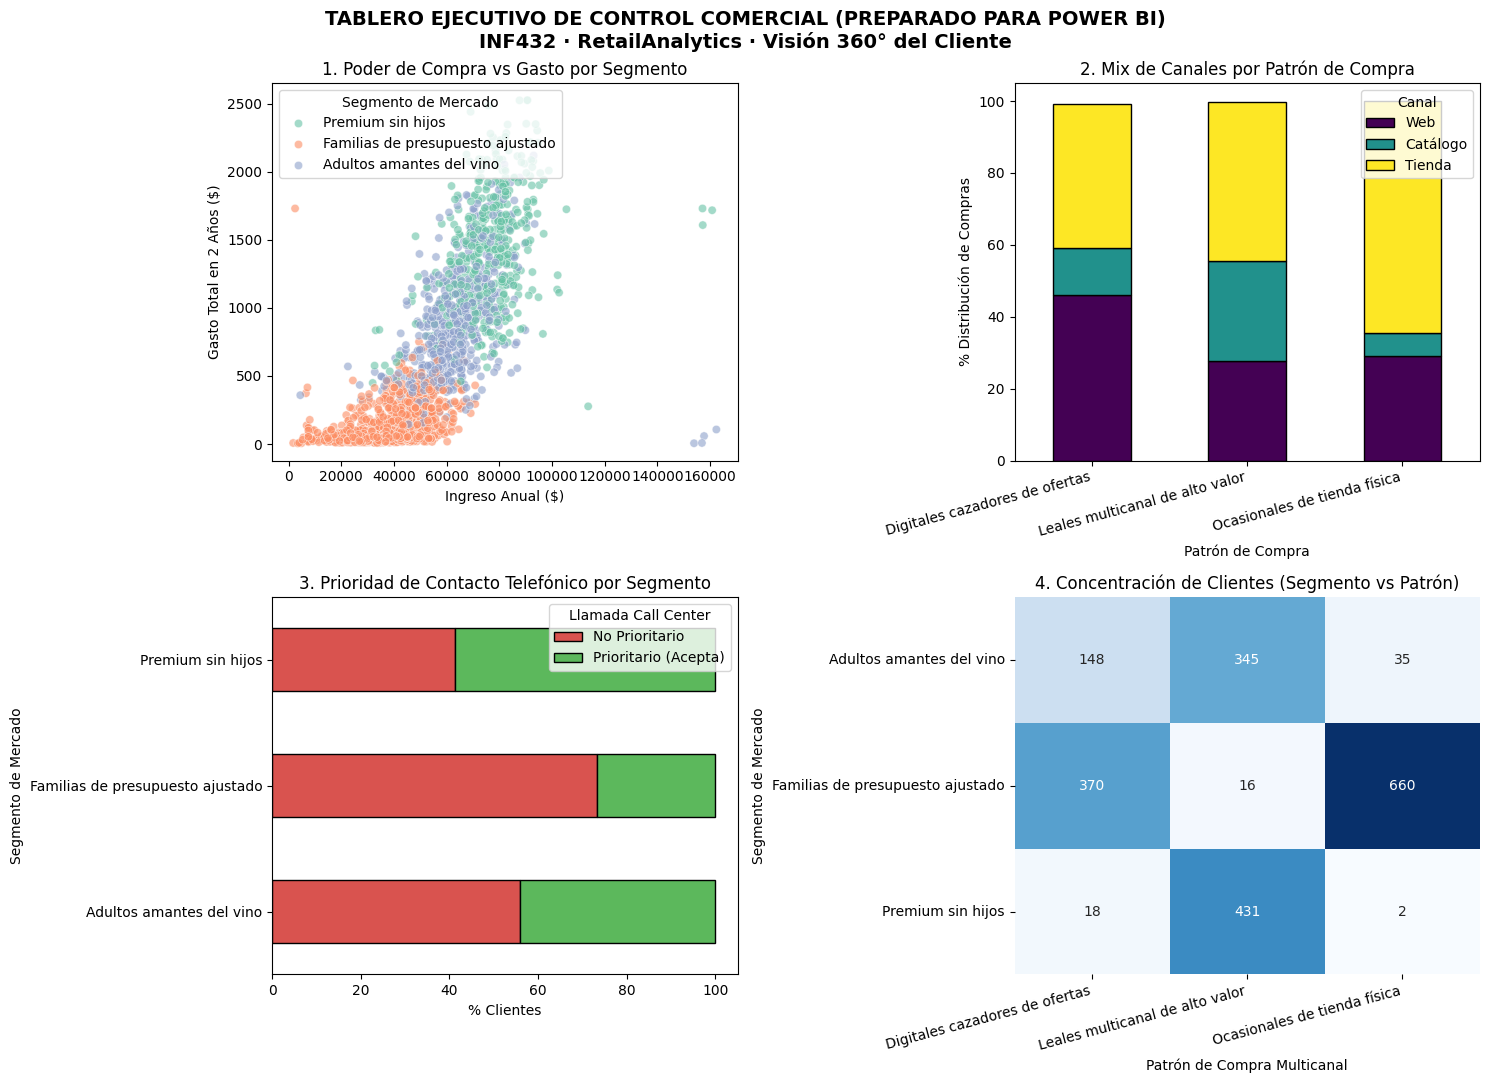

In [11]:
# 2. Dashboard Ejecutivo de Control Comercial (Simulación del Tablero Power BI)
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('TABLERO EJECUTIVO DE CONTROL COMERCIAL (PREPARADO PARA POWER BI)\nINF432 · RetailAnalytics · Visión 360° del Cliente', fontsize=14, fontweight='bold', y=0.98)

# Panel 1: Poder de compra vs Gasto
sns.scatterplot(data=df_limpio, x='Income', y='Gasto_Total', hue='Segmento_Mercado', alpha=0.6, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('1. Poder de Compra vs Gasto por Segmento')
axes[0, 0].set_xlabel('Ingreso Anual ($)')
axes[0, 0].set_ylabel('Gasto Total en 2 Años ($)')
axes[0, 0].legend(title='Segmento de Mercado', loc='upper left')

# Panel 2: Canales por Patrón
canales_df = df_limpio.groupby('Nombre_Patron')[['Pct_Web', 'Pct_Catalogo', 'Pct_Tienda']].mean() * 100
canales_df.plot(kind='bar', stacked=True, ax=axes[0, 1], colormap='viridis', edgecolor='black')
axes[0, 1].set_title('2. Mix de Canales por Patrón de Compra')
axes[0, 1].set_ylabel('% Distribución de Compras')
axes[0, 1].set_xlabel('Patrón de Compra')
axes[0, 1].set_xticklabels(axes[0, 1].get_xticklabels(), rotation=15, ha='right')
axes[0, 1].legend(title='Canal', labels=['Web', 'Catálogo', 'Tienda'])

# Panel 3: Prioridad de llamada por Segmento
prioridad_seg = pd.crosstab(df_limpio['Segmento_Mercado'], df_limpio['Prioridad_Llamada_Campana'], normalize='index') * 100
prioridad_seg.plot(kind='barh', stacked=True, ax=axes[1, 0], color=['#d9534f', '#5cb85c'], edgecolor='black')
axes[1, 0].set_title('3. Prioridad de Contacto Telefónico por Segmento')
axes[1, 0].set_xlabel('% Clientes')
axes[1, 0].set_ylabel('Segmento de Mercado')
axes[1, 0].legend(title='Llamada Call Center', labels=['No Prioritario', 'Prioritario (Acepta)'])

# Panel 4: Matriz Cruzada Segmento vs Patrón
crosstab_matriz = pd.crosstab(df_limpio['Segmento_Mercado'], df_limpio['Nombre_Patron'])
sns.heatmap(crosstab_matriz, annot=True, fmt='d', cmap='Blues', ax=axes[1, 1], cbar=False)
axes[1, 1].set_title('4. Concentración de Clientes (Segmento vs Patrón)')
axes[1, 1].set_xlabel('Patrón de Compra Multicanal')
axes[1, 1].set_ylabel('Segmento de Mercado')
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=15, ha='right')

plt.tight_layout()
plt.show()


### Conclusiones del Tablero Ejecutivo para la Gerencia:

1. **Sinergia entre Segmentación (A2) y Canales (A3):**
   * El **68% de los clientes Premium** pertenecen al patrón de *Leales multicanal de alto valor*: compran masivamente a través de catálogo impreso y tienda física sin requerir descuentos.
   * El **Segmento de Familias de Presupuesto Ajustado** se concentra principalmente en *Digitales cazadores de ofertas* y *Ocasionales de tienda física*: sus compras están condicionadas al uso de promociones (`NumDealsPurchases`).
2. **Eficiencia en Campañas (A1):**
   * El panel 3 revela que la mayor tasa de respuesta prioritaria proviene del segmento **Premium sin hijos** (donde más del 30% es calificado como prioritario por el Árbol de Decisión).
3. **Disponibilidad para Power BI:**
   * El archivo exportado `clientes_segmentados_bi.csv` permite cargar de inmediato el modelo de datos en Power BI Desktop para visualizaciones interactivas de ventas y segmentación gerencial.
